# Mixture of experts at 6 h - normal expert, spike expert and gate

Project 19 (air quality forecasting via gradient boosting and LSTM models) - Team T024, Section A.

**Why.** In Phase 1 (`03_phase1_models.ipynb`, step 10) the 6 h blend predicts hours above 150 µg/m³ about 55 µg/m³
too low on average, and those hours carry about half of its squared error. The Phase 1 spike expert got weight 0 in
the blend, because a fixed weight applies to every hour and the spike expert aims high on all of them. Here a gate
decides hour by hour how much the spike expert counts.

**Design.**

| Part | Model | Trained on |
|---|---|---|
| normal expert | the Phase 1 blend: 0.6 * XGBoost (5 seeds) + 0.4 * Ridge, settings frozen in `reports/phase1/cv_choices.json` | all training hours |
| spike expert | XGBoost with squared error and the same settings, 5 seeds | training hours whose target is above 150 |
| gate | XGBoost classifier with the same settings, 5 seeds: probability p that PM2.5 at t + 6 is above 150 | all training hours |

Two ways to combine them:

- `moe_gate`: `normal + lambda * p * (spike - normal)`. The normal expert is the Phase 1 blend unchanged, and lambda
  is chosen on cv1 to cv3. lambda = 0 gives the Phase 1 blend back, so the validation score cannot get worse.
- `moe_split`: a second normal expert trained only on hours at or below 150, and `(1 - p) * normal + p * spike`.
  If p is the true probability and each expert predicts the mean of its group, this is the overall mean, which is
  what RMSE rewards.

The gate reads the same inputs as the experts, not their forecasts, so no forecast feeds into it. 150 is the
"heavily polluted" boundary of HJ 633-2012 and the episode definition used in Phase 1.

**Rules.** Horizon 6 h only, the headline chosen in Phase 1. Every choice is made on cv1 to cv3 (2011 to 2013) by
pooled RMSE, so the cv scores are slightly optimistic. The 2014 test year was scored once for Phase 1 and is not
used here: this notebook never builds the test fold.

| Step | What |
|---|---|
| 0 | setup, frozen Phase 1 settings |
| 1 | features and datasets, the same as Phase 1 |
| 2 | normal expert, checked against the Phase 1 score |
| 3 | spike expert |
| 4 | gate and how well it spots episodes |
| 5 | normal expert for quiet hours |
| 6 | combining the experts |
| 7 | results and error breakdown |
| 8 | seed check |
| 9 | forecast window |
| 10 | findings |
| 11 | timings |

## 0. Setup

In [1]:
import json
import sys
import time
from contextlib import contextmanager
from functools import cache
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss, roc_auc_score

from aqf import viz
from aqf.config import load_config
from aqf.data.pipeline import run
from aqf.data.split import make_folds
from aqf.features import build, fold_xy
from aqf.metrics import score
from aqf.models import baselines, fit_gate, fit_ridge, fit_xgb, gate_blend

%config InlineBackend.figure_format = "retina"
pd.set_option("display.width", 120)
pd.set_option("display.precision", 3)
viz.use_style()

dcfg = load_config("configs/data.yaml")
cfg = load_config("configs/phase1.yaml")
mcfg = load_config("configs/moe.yaml")
OUT = mcfg["paths"]["out"]
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(dcfg["paths"]["interim"]) if dcfg["paths"]["interim"].exists() else run(dcfg)[0]
FOLD = {f["name"]: f for f in make_folds(df.index, **dcfg["split"]) if f["name"] != "test"}
CVN = list(FOLD)

H, EP, xc, SEEDS = mcfg["h"], mcfg["episode"], cfg["xgb"], cfg["ensemble_seeds"]
P1 = json.loads(mcfg["paths"]["phase1"].read_text())
PARAMS = {**xc["base"], **P1["xgb"][str(H)]}
DELTA = P1["xgb_target"][str(H)] == "change"
ALPHA, RLOG = P1["ridge"][str(H)]["alpha"], P1["ridge"][str(H)]["log_target"]
W = P1["blend"][str(H)]
assert W["spike"] == 0 and not P1["xgb_log_target"] and P1["select"] == "rmse"

TIMES = {}


@contextmanager
def timed(step):
    t0 = time.perf_counter()
    yield
    TIMES[step] = round(time.perf_counter() - t0, 1)
    print(f"{step}: {TIMES[step]} s")


CVN, H, EP, P1["xgb"][str(H)], W

(['cv1', 'cv2', 'cv3'],
 6,
 150,
 {'max_depth': 4,
  'min_child_weight': 20,
  'subsample': 1.0,
  'colsample_bytree': 0.5,
  'reg_lambda': 1.0},
 {'xgb_seeds': 0.6, 'spike': 0.0, 'ridge': 0.4})

## 1. Features and datasets

The same features and folds as Phase 1. Subsets for the breakdown, all on the eval hours:

| Subset | Hours |
|---|---|
| quiet | PM2.5 at t + 6 at most 150 |
| episode | PM2.5 at t + 6 above 150 |
| onset | episode hours where PM2.5 at t was at most 150, so the episode starts within 6 h |
| clearing | hours where PM2.5 at t was above 150 and at t + 6 at most 150 |

In [2]:
with timed("features"):
    F, _ = build(df, cfg["features"])


@cache
def xy(name):
    return fold_xy(F, df, FOLD[name], H)


Y = pd.concat([xy(n)[3] for n in CVN])
PM0 = pd.concat([xy(n)[2]["pm_0"] for n in CVN])
EPI = (Y > EP).to_numpy()
HIGH0 = (PM0 > EP).to_numpy()
SUB = {"all": np.ones(len(Y), bool), "quiet": ~EPI, "episode": EPI,
       "onset": EPI & ~HIGH0, "clearing": ~EPI & HIGH0}
P = {}


def cat(d):
    return np.concatenate([d[n] for n in CVN])


def pooled(model):
    return cat(P[model])


pd.DataFrame({"hours": {k: int(v.sum()) for k, v in SUB.items()}})

features: 0.0 s


,hours
all,24417
quiet,19248
episode,5169
onset,1688
clearing,1697


## 2. Normal expert

The Phase 1 blend at 6 h, rebuilt from the frozen settings. The check below compares it with the score Phase 1
saved in `reports/phase1/cv_scores.csv`.

In [3]:
def train(n, rows=None):
    """Training set of fold n, optionally only the rows where `rows(y)` is true."""
    X_tr, y_tr, X_ev, _ = xy(n)
    if rows is not None:
        keep = rows(y_tr).to_numpy()
        X_tr, y_tr = X_tr[keep], y_tr[keep]
    return X_tr, y_tr, X_ev


def xgb_seeds(rows=None, seeds=SEEDS):
    out = {}
    for n in CVN:
        X_tr, y_tr, X_ev = train(n, rows)
        runs = [fit_xgb(X_tr, y_tr, PARAMS, xc["tail_hours"], H, False, False, s, DELTA)[0].predict(X_ev)
                for s in seeds]
        out[n] = np.mean(runs, axis=0)
    return out


def blend(rows=None, seeds=SEEDS):
    xs = xgb_seeds(rows, seeds)
    rg = {n: fit_ridge(*train(n, rows)[:2], ALPHA, RLOG).predict(train(n)[2]) for n in CVN}
    return {n: W["xgb_seeds"] * xs[n] + W["ridge"] * rg[n] for n in CVN}


with timed("normal expert"):
    P["normal"] = blend()
P["persistence"] = {n: baselines(df, H).loc[xy(n)[2].index, "persistence"].to_numpy() for n in CVN}

ref = pd.read_csv(mcfg["paths"]["phase1_scores"]).query("h == @H and model == 'blend'")["rmse"].item()
s = score(Y, pooled("normal"))
assert np.isclose(s["rmse"], ref), (s["rmse"], ref)
e2 = (pooled("normal") - Y.to_numpy()) ** 2
print(f"normal expert RMSE {s['rmse']:.3f}, Phase 1 blend {ref:.3f}: reproduced")
print(f"episode hours: {EPI.mean():.1%} of hours, {e2[EPI].sum() / e2.sum():.1%} of the squared error")

normal expert: 9.8 s
normal expert RMSE 56.330, Phase 1 blend 56.330: reproduced
episode hours: 21.2% of hours, 50.6% of the squared error


## 3. Spike expert

XGBoost with squared error, trained only on hours whose target is above 150, so it predicts how high PM2.5 goes
given that an episode is under way at t + 6. Same settings and early stopping as the normal expert, 5 seeds.

In [4]:
with timed("spike expert"):
    P["spike"] = xgb_seeds(lambda y: y > EP)
pd.DataFrame({"training hours": {n: len(train(n, lambda y: y > EP)[1]) for n in CVN},
              "of all training hours": {n: len(xy(n)[1]) for n in CVN}})

spike expert: 7.1 s


,training hours,of all training hours
cv1,1952,8073
cv2,3735,16105
cv3,5358,24400


## 4. Gate

An XGBoost classifier for P(PM2.5 at t + 6 > 150), trained on all training hours with the same settings, mean of 5
seeds. How well it separates episode hours from quiet ones is measured with:

- AUC: the chance that a random episode hour gets a higher p than a random quiet hour (0.5 is guessing, 1 is
  perfect). `pm_0` alone, the PM2.5 level at t, is the reference: a gate must beat "it is high now".
- onset AUC: the same, only on hours where PM2.5 at t is at most 150, so the gate has to see an episode coming.
- clearing AUC: only on hours where PM2.5 at t is above 150, so the gate has to see an episode ending.
- Brier score: mean squared error of p against the 0 / 1 outcome (lower is better).

In [5]:
def gate(n, seed):
    X_tr, y_tr, X_ev, _ = xy(n)
    return fit_gate(X_tr, y_tr, EP, PARAMS, xc["tail_hours"], H, seed)[0].predict_proba(X_ev)[:, 1]


def gates(seeds=SEEDS):
    return {n: np.mean([gate(n, s) for s in seeds], axis=0) for n in CVN}


with timed("gate"):
    G = gates()
g, pm0 = cat(G), PM0.to_numpy()
on, cl = ~HIGH0, HIGH0
gate_q = pd.DataFrame({
    "gate p": {"AUC": roc_auc_score(EPI, g), "onset AUC": roc_auc_score(EPI[on], g[on]),
               "clearing AUC": roc_auc_score(EPI[cl], g[cl]), "Brier": brier_score_loss(EPI, g)},
    "pm_0 alone": {"AUC": roc_auc_score(EPI, pm0), "onset AUC": roc_auc_score(EPI[on], pm0[on]),
                   "clearing AUC": roc_auc_score(EPI[cl], pm0[cl]), "Brier": np.nan},
})
gate_q.to_csv(OUT / "cv_gate.csv")
gate_q

gate: 11.3 s


,gate p,pm_0 alone
AUC,0.923,0.904
onset AUC,0.883,0.846
clearing AUC,0.734,0.645
Brier,0.088,NaN


Calibration: within each band of p, the share of hours that really were episodes. A calibrated gate has the two
columns close.

In [6]:
band = pd.cut(g, [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1], include_lowest=True)
calib = pd.DataFrame({"p": g, "episode": EPI}).groupby(band, observed=True).agg(
    hours=("p", "size"), mean_p=("p", "mean"), episode_rate=("episode", "mean"))
calib.to_csv(OUT / "cv_gate_calibration.csv")
calib

,hours,mean_p,episode_rate
"(-0.001, 0.1]",13664,0.025,0.020
"(0.1, 0.3]",3893,0.182,0.163
"(0.3, 0.5]",2021,0.394,0.368
"(0.5, 0.7]",1989,0.603,0.612
"(0.7, 0.9]",2594,0.799,0.800
"(0.9, 1.0]",256,0.923,0.891


## 5. Normal expert for quiet hours

For `moe_split` the normal expert is trained only on hours whose target is at most 150, with the Phase 1 recipe
(0.6 * XGBoost with 5 seeds + 0.4 * Ridge, same settings).

In [7]:
with timed("quiet expert"):
    P["normal_quiet"] = blend(lambda y: y <= EP)

quiet expert: 11.8 s


## 6. Combining the experts

- `moe_gate`: lambda from 0 to 1 by pooled RMSE on cv1 to cv3.
- `moe_split`: `(1 - p) * normal_quiet + p * spike`, nothing tuned.
- `moe_split_hard`: the same experts with a hard switch (spike expert when p > 0.5), to show what a hard gate costs.
- `oracle_gate` and `oracle_split`: p replaced by the true answer (1 for episode hours, 0 otherwise). Not forecasts,
  since they use the label; they show how good the experts are if the gate were perfect, so the gap to the real
  gate is what better episode detection could still win.

In [8]:
def mix(normal, lam, gate=G):
    return {n: gate_blend(P[normal][n], P["spike"][n], gate[n], lam) for n in CVN}


def pooled_mix(normal, lam, gate=G):
    return cat(mix(normal, lam, gate))


LAMS = np.round(np.arange(0, 1 + 1e-9, mcfg["lam_step"]), 2)
curve = pd.DataFrame([{"lambda": float(l), **score(Y, pooled_mix("normal", l))} for l in LAMS]).set_index("lambda")
LAM = float(curve["rmse"].idxmin())
curve.to_csv(OUT / "cv_lambda.csv")

HARD = {n: (G[n] > mcfg["hard_cut"]).astype(float) for n in CVN}
ORACLE = {n: (xy(n)[3] > EP).to_numpy().astype(float) for n in CVN}
P["moe_gate"] = mix("normal", LAM)
P["moe_split"] = mix("normal_quiet", 1.0)
P["moe_split_hard"] = mix("normal_quiet", 1.0, HARD)
P["oracle_gate"] = mix("normal", 1.0, ORACLE)
P["oracle_split"] = mix("normal_quiet", 1.0, ORACLE)

choices = {"h": H, "episode": EP, "lambda": LAM, "hard_cut": mcfg["hard_cut"], "phase1_settings": P1["xgb"][str(H)],
           "phase1_blend": W, "ridge": P1["ridge"][str(H)]}
(OUT / "cv_choices.json").write_text(json.dumps(choices, indent=2))
print("chosen lambda:", LAM)
curve[["rmse", "mae", "r2", "bias"]]

chosen lambda: 0.1


,rmse,mae,r2,bias
lambda,,,,
0.0,56.330,36.410,0.621,1.634
0.1,56.312,36.401,0.621,2.928
0.2,56.365,36.433,0.620,4.222
0.3,56.487,36.510,0.619,5.516
0.4,56.678,36.637,0.616,6.810
0.5,56.937,36.814,0.612,8.104
0.6,57.265,37.036,0.608,9.399
0.7,57.658,37.304,0.603,10.693
0.8,58.117,37.613,0.596,11.987


## 7. Results and error breakdown

Pooled over cv1 to cv3 at 6 h. Skill is 1 - RMSE / RMSE of persistence. `normal` is the Phase 1 blend.

In [9]:
MODELS = ["persistence", "normal", "spike", "normal_quiet", "moe_gate", "moe_split", "moe_split_hard",
          "oracle_gate", "oracle_split"]
ref = score(Y, pooled("persistence"))
scores = pd.DataFrame([{"model": m, **score(Y, pooled(m))} for m in MODELS]).set_index("model")
scores["skill_rmse"] = 1 - scores["rmse"] / ref["rmse"]
scores.to_csv(OUT / "cv_scores.csv")
scores

,mae,rmse,r2,bias,skill_rmse
model,,,,,
persistence,40.231,65.772,0.483,0.057,0.000
normal,36.410,56.330,0.621,1.634,0.144
spike,115.811,129.733,-1.012,106.681,-0.972
normal_quiet,49.377,84.272,0.151,-30.666,-0.281
moe_gate,36.401,56.312,0.621,2.928,0.144
moe_split,35.991,56.256,0.622,2.209,0.145
moe_split_hard,38.117,61.241,0.552,1.608,0.069
oracle_gate,32.410,49.584,0.706,13.879,0.246
oracle_split,27.286,39.457,0.814,1.633,0.400


In [10]:
rows = []
for m in MODELS:
    p = pooled(m)
    for name, mask in SUB.items():
        s = score(Y[mask], p[mask])
        rows.append({"subset": name, "model": m, "hours": int(mask.sum()),
                     "mae": s["mae"], "rmse": s["rmse"], "bias": s["bias"]})
bd = pd.DataFrame(rows)
bd.to_csv(OUT / "cv_breakdown.csv", index=False)
bd.pivot(index="model", columns="subset", values="rmse").loc[MODELS, list(SUB)]

subset,all,quiet,episode,onset,clearing
model,,,,,
persistence,65.772,57.881,89.213,108.170,162.626
normal,56.330,44.594,87.084,92.423,111.628
spike,129.733,142.198,64.875,54.927,164.422
normal_quiet,84.272,29.063,174.360,120.681,42.263
moe_gate,56.312,45.500,85.267,90.949,114.339
moe_split,56.256,44.742,86.574,92.638,113.196
moe_split_hard,61.241,50.897,89.833,108.188,140.138
oracle_gate,49.584,44.594,64.875,54.927,111.628
oracle_split,39.457,29.063,64.875,54.927,42.263


In [11]:
bd.pivot(index="model", columns="subset", values="bias").loc[MODELS, list(SUB)]

subset,all,quiet,episode,onset,clearing
model,,,,,
persistence,0.057,9.504,-35.122,-86.220,133.139
normal,1.634,16.923,-55.296,-70.005,89.319
spike,106.681,134.646,2.546,8.495,148.364
normal_quiet,-30.666,1.387,-150.024,-105.328,3.608
moe_gate,2.928,17.782,-52.382,-67.860,92.310
moe_split,2.209,16.738,-51.893,-68.670,87.989
moe_split_hard,1.608,11.341,-34.633,-79.016,98.120
oracle_gate,13.879,16.923,2.546,8.495,89.319
oracle_split,1.633,1.387,2.546,8.495,3.608


## 8. Seed check

The gains above are small, so the normal expert, `moe_gate` (same lambda) and `moe_split` are rebuilt with three
sets of 5 seeds; the first set is the one used above. A real gain should show up in every set and be larger than
how much the normal expert itself moves between sets.

In [12]:
with timed("seed check"):
    rows = []
    for seeds in mcfg["seed_sets"]:
        normal, quiet = blend(seeds=seeds), blend(lambda y: y <= EP, seeds)
        spike, gp = xgb_seeds(lambda y: y > EP, seeds), gates(seeds)
        runs = {"normal": normal, "moe_gate": {n: gate_blend(normal[n], spike[n], gp[n], LAM) for n in CVN},
                "moe_split": {n: gate_blend(quiet[n], spike[n], gp[n]) for n in CVN}}
        for m, pr in runs.items():
            rows.append({"seeds": ", ".join(map(str, seeds)), "model": m, **score(Y, cat(pr))})
seed_check = pd.DataFrame(rows)
seed_check.to_csv(OUT / "cv_seed_check.csv", index=False)
seed_check.pivot(index="seeds", columns="model", values=["rmse", "mae"]).loc[seed_check["seeds"].unique()]

seed check: 110.0 s


rmse                        mae                  
model              moe_gate moe_split  normal moe_gate moe_split  normal
seeds                                                                   
0, 1, 2, 3, 4        56.312    56.256  56.330   36.401    35.991  36.410
5, 6, 7, 8, 9        56.325    56.340  56.345   36.433    36.028  36.445
10, 11, 12, 13, 14   56.414    56.244  56.445   36.446    35.997  36.461

## 9. Forecast window

The January 2013 episode from Phase 1 (validation year of cv3), forecasts plotted at their target time, with the
better of the two real mixtures.

'moe_split'

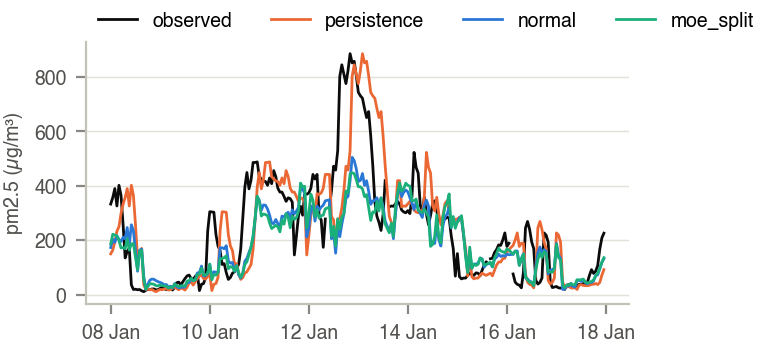

In [13]:
BEST = min(["moe_gate", "moe_split"], key=lambda m: scores.loc[m, "rmse"])


def at_target(model):
    n = CVN[-1]
    return pd.Series(P[model][n], index=xy(n)[2].index + pd.Timedelta(hours=H))


fig = viz.forecast_window(df["pm25"], {m: at_target(m) for m in ["persistence", "normal", BEST]},
                          "2013-01-08", "2013-01-17")
BEST

## 10. Findings

Numbers from the cells above (pooled cv1 to cv3, 6 h, µg/m³).

- **The normal expert is the Phase 1 blend**: RMSE 56.330, identical to Phase 1.
- **The gate beats "it is high now"**: AUC 0.923 against 0.904 for the PM2.5 level at t; for onsets 0.883 against
  0.846; for clearing 0.734 against 0.645. Its probabilities are calibrated: in every band of p the observed episode
  rate is within 0.04 of the mean p.
- **`moe_split` lowers MAE, not RMSE**: MAE 35.991 against 36.410 (1.15% lower). In all three seed sets MAE drops
  by 0.42 to 0.46, while the normal expert itself moves by 0.05 between sets, so the MAE gain is real. RMSE drops by
  0.005 to 0.202, within the 0.115 the normal expert moves between sets, so there is no clear RMSE gain.
- **`moe_gate` keeps almost nothing of the spike expert**: lambda = 0.1, RMSE 56.312.
- **A hard switch hurts**: RMSE 61.241. A wrong call puts the spike forecast on a quiet hour or the quiet forecast on
  an episode.
- **The experts are not the problem, the gate is**: with the true episode labels as the gate, the same experts reach
  RMSE 39.457 (`oracle_split`). The gap from 56.256 to 39.457 is what better detection of episode starts and ends
  could still win; clearing (AUC 0.734) is the weakest part.

Why the gain is small: with calibrated probabilities and experts that each predict the mean of their group,
`(1 - p) * normal + p * spike` estimates the same overall mean as the single Phase 1 model, from the same inputs. It
can only win where training on one group finds patterns the single model smooths over. A larger gain needs a gate
with more information about the next 6 hours, such as a longer history (an LSTM gate in Phase 2) or a weather
forecast.

## 11. Timings

In [14]:
(OUT / "timings.json").write_text(json.dumps(TIMES, indent=2))
pd.Series(TIMES, name="seconds").to_frame()

,seconds
features,0.0
normal expert,9.8
spike expert,7.1
gate,11.3
quiet expert,11.8
seed check,110.0
